# Molten nitrate-salt corrosion: unified exploratory analysis and model comparison

**Models:** A seeded random forest was used as a baseline model. Classical SVR RBF, GP kernels, original MLP 16→8, two-branch fusion ANN 16/8→16, and the provided six-logical-qubit **mid-circuit fusion VQC**. All models use the **same cleaned observations, the same external train/test partitions, and the same targets and original-unit metrics**. Every model receives the **same 22 underlying input variables** (3 experimental conditions, 16 elemental compositions, 3 headgas indicators). Each retains its own architecture, optimizer, and fold-fitted preprocessing. This is an **equal-feature, unequal-capacity** architectural comparison.

**Run in Google Colab**: upload your original 25-column CSV or XLSX, edit `SOURCE_PATH` below, install dependencies, then run all. Quantum evaluation is expensive; use `RUN_QUANTUM=True` to enable it. All results are generated from the file, not hard-coded.

**Interpretation of experimental settings:** random row holdout is interpolation-like and may leak closely related tests; composition-profile holdout directly addresses unseen compositions; the isolated-profile scenario tests only the five most compositionally isolated profiles; publication holdout assesses cross-study generalization and can additionally involve unfamiliar alloys. A single split can be unstable with so few papers. CV summaries cover *all* outer held-out predictions under a fixed splitter; use per-group data in exports to investigate distribution shift. All model selection occurs *only on training partitions*.

**Data caveats:** `'<3'` is upper-censored, not equal to 3; main analysis uses 3 as a declared upper-bound proxy, and secondary sensitivity uses 1.5. Inequality elemental values are replaced with their upper bound and numeric ranges with midpoints. These are approximations, not measurements. The original cleaning notebook flags a temperature of **4765°C**, which requires source verification; the default **retains and flags** it rather than silently guessing a correction. Composition profiles are based on 16 reported element fractions, rounded to 2 decimals; identical recorded compositions belong to the same group.

In [39]:
# Colab setup (uncomment if needed)
# from google.colab import drive
# drive.mount('/content/drive')
# %uv add pandas numpy scipy scikit-learn matplotlib seaborn openpyxl pyarrow
# %uv add torch pennylane
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, StandardScaler
from sklearn.svm import SVR
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
SOURCE_PATH = Path(
    r"..\data\raw\corrosion_data.csv"
).resolve()  # '/content/Literature Review - Corrosion Data (1).csv' # OR a local CSV
SHEET_NAME = "Corrosion Data"
OUTPUT_DIR = (
    Path(r"..\content\corrosion_unified_results")
    if Path(r"..\content").exists()
    else Path(r"..\corrosion_unified_results")
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_QUANTUM = False  # Set False to debug classical models quickly
RUN_SENSITIVITY = False  # second full run using '<3' -> 1.5
RUN_NESTED_TUNING = (
    True  # training-only grid search for SVR/GPR; slow on quantum folds but separate
)
RUN_RANDOM_SPLIT = True
RUN_ALLOY_SPLIT = True
RUN_ISOLATED_COMPOSITION_SPLIT = True  # five most isolated composition profiles
RUN_STUDY_SPLIT = True
QUANTUM_EPOCHS = 60
QUANTUM_BATCH_SIZE = 16

## 1. Data provenance, consistent cleaning and audit

In [40]:
from pathlib import Path

import numpy as np
from IPython.display import display

# ============================================================
# 2. FEATURE DEFINITIONS
# ============================================================

ELEMENTS_RAW = [
    "Ni (wt.%)",
    "Cr (wt.%)",
    "Fe (wt.%)",
    "C (wt.%)",
    "Mn (wt.%)",
    "Si (wt.%)",
    "N (wt.%)",
    "Nb (wt.%)",
    "Co (wt.%)",
    "Mo (wt.%)",
    "Al (wt.%)",
    "Ti (wt.%)",
    "Cu (wt.%)",
    "W (wt.%)",
    "P (wt.%)",
    "S (wt.%)",
]

ELEMENTS = [c.replace(" (wt.%)", "").lower() + "_wt_pct" for c in ELEMENTS_RAW]

RENAMES = {
    "Paper ID": "paper_id",
    "Alloy": "alloy",
    "Temperature (celcius)": "temperature_c",
    "Exposure Time (hours)": "exposure_time_h",
    "Flow (m/s)": "flow_m_per_s",
    "Corrosion Rate (μm/yr)": "corrosion_rate_um_per_year",
}

RENAMES.update(dict(zip(ELEMENTS_RAW, ELEMENTS)))

COND = ["temperature_c", "exposure_time_h", "flow_m_per_s"]

GASES = ["headgas_air", "headgas_n2", "headgas_o2_sealed_loop"]

FULL_FEATURES = COND + ELEMENTS + GASES

assert len(FULL_FEATURES) == 22

# ============================================================
# 3. ELEMENTAL COMPOSITION PARSING
# ============================================================


def parse_element(value):
    """Parse an elemental composition, including bounds and ranges."""

    if pd.isna(value):
        return np.nan

    s = str(value).strip().replace("≤", "<=")

    # Upper-bound composition, e.g. <=0.025
    if s.startswith("<="):
        return float(s[2:].strip())

    # Composition ranges, e.g. 0.85-1.2
    match = re.fullmatch(r"([0-9]+(?:\.[0-9]+)?)\s*-\s*([0-9]+(?:\.[0-9]+)?)", s)

    if match:
        lower = float(match.group(1))
        upper = float(match.group(2))
        return (lower + upper) / 2

    return float(s)


# ============================================================
# 4. SHARED DATA CLEANING
# ============================================================


def load_clean(source=SOURCE_PATH, censored_proxy=3.0):
    """Load and clean corrosion observations from a CSV file."""

    path = Path(source)

    if not path.exists():
        raise FileNotFoundError(
            f"CSV file not found: {path}\n"
            "Upload the CSV to Colab and check SOURCE_PATH."
        )

    # Read original CSV
    raw = pd.read_csv(path)

    print("Original dataset shape:", raw.shape)

    # Validate required columns
    required = [
        "Paper ID",
        "Alloy",
        "Salt",
        "Headgas",
        "Temperature (celcius)",
        "Exposure Time (hours)",
        "Flow (m/s)",
        "Corrosion Rate (μm/yr)",
        *ELEMENTS_RAW,
    ]

    missing = sorted(set(required) - set(raw.columns))

    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    # Keep original dataset unchanged
    df = raw.copy()

    # --------------------------------------------------------
    # Corrosion-rate cleaning
    # --------------------------------------------------------

    rate_string = df["Corrosion Rate (μm/yr)"].astype(str).str.strip()

    # Identify censored targets such as <3
    df["censored_rate"] = rate_string.str.match(r"^<\s*[0-9.]+$")

    # Use 3.0 as a documented proxy for <3
    rate_string = rate_string.str.replace(
        r"^<\s*[0-9.]+$", str(censored_proxy), regex=True
    )

    df["Corrosion Rate (μm/yr)"] = pd.to_numeric(rate_string, errors="coerce")

    # --------------------------------------------------------
    # Elemental composition cleaning
    # --------------------------------------------------------

    for col in ELEMENTS_RAW:
        df[col] = df[col].apply(parse_element)

    # --------------------------------------------------------
    # Experimental conditions
    # --------------------------------------------------------

    for col in ["Temperature (celcius)", "Exposure Time (hours)", "Flow (m/s)"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # --------------------------------------------------------
    # Remove incomplete observations
    # --------------------------------------------------------

    required_nonmissing = [
        "Paper ID",
        "Alloy",
        "Headgas",
        "Corrosion Rate (μm/yr)",
        "Temperature (celcius)",
        "Exposure Time (hours)",
        "Flow (m/s)",
        *ELEMENTS_RAW,
    ]

    df = df.dropna(subset=required_nonmissing).copy()

    # Exclude invalid target and exposure time
    df = df.loc[
        (df["Corrosion Rate (μm/yr)"] >= 0) & (df["Exposure Time (hours)"] >= 0)
    ].copy()

    # --------------------------------------------------------
    # Composition validation
    # --------------------------------------------------------

    df["recomputed_composition"] = df[ELEMENTS_RAW].sum(axis=1)

    df = df.loc[df["recomputed_composition"].between(95, 105)].copy()

    if df.empty:
        raise ValueError("No observations remain after cleaning.")

    # --------------------------------------------------------
    # Validate salt system
    # --------------------------------------------------------

    if df["Salt"].nunique() != 1:
        raise ValueError("Multiple salt systems detected.")

    # --------------------------------------------------------
    # Headgas one-hot encoding
    # --------------------------------------------------------

    allowed = {"air", "N2", "O2 (sealed loop)"}

    unexpected = set(df["Headgas"]) - allowed

    if unexpected:
        raise ValueError(f"Unexpected headgas categories: {unexpected}")

    gas_mapping = {
        "headgas_air": "air",
        "headgas_n2": "N2",
        "headgas_o2_sealed_loop": "O2 (sealed loop)",
    }

    for new_col, category in gas_mapping.items():
        df[new_col] = (df["Headgas"] == category).astype(int)

    # --------------------------------------------------------
    # Rename columns
    # --------------------------------------------------------

    df = df.rename(columns=RENAMES)

    df["paper_id"] = df["paper_id"].astype(str).str.strip()

    df["alloy"] = df["alloy"].astype(str).str.strip()

    # --------------------------------------------------------
    # Additional engineered variables
    # --------------------------------------------------------

    df["log_time"] = np.log1p(df["exposure_time_h"])

    df["atmosphere_oxidizing"] = df["headgas_air"] + df["headgas_o2_sealed_loop"]

    # Composition-based alloy grouping
    df["composition_profile"] = (
        df[ELEMENTS]
        .round(2)
        .apply(lambda row: "|".join(f"{x:.2f}" for x in row), axis=1)
    )

    # Preserve original row indices
    df["source_row"] = df.index.astype(int)

    # --------------------------------------------------------
    # Final validation
    # --------------------------------------------------------

    assert df[FULL_FEATURES + ["corrosion_rate_um_per_year"]].notna().all().all()

    assert len(FULL_FEATURES) == 22

    return df.reset_index(drop=True), raw


# ============================================================
# 5. LOAD CLEAN DATA
# ============================================================

data, raw = load_clean()

print("\n========== DATA SUMMARY ==========")

print("RAW SHAPE:", raw.shape)
print("CLEAN SHAPE:", data.shape)

print("PAPERS:", data["paper_id"].nunique())
print("ALLOY NAMES:", data["alloy"].nunique())

print("COMPOSITION PROFILES:", data["composition_profile"].nunique())

print("CENSORED TARGET ROWS:", int(data["censored_rate"].sum()))

print("NUMBER OF MODEL FEATURES:", len(FULL_FEATURES))

# ============================================================
# 6. FLAG SUSPICIOUS TEMPERATURES
# ============================================================

print("\nTemperature values requiring source review:")

display(
    data.loc[
        data["temperature_c"] > 1000,
        ["paper_id", "alloy", "temperature_c", "source_row"],
    ]
)

# ============================================================
# 7. CHECK COMPOSITION TOTALS
# ============================================================

print("\nComposition totals:")

print(data[ELEMENTS].sum(axis=1).agg(["min", "max"]).to_dict())

# ============================================================
# 8. SAVE SHARED CLEAN DATASET
# ============================================================

OUTPUT_PATH = OUTPUT_DIR / "shared_clean_data.csv"

data.to_csv(OUTPUT_PATH, index=False)

print("\nCleaned dataset saved to:")
print(OUTPUT_PATH)

# ============================================================
# 9. EXTRACT MODEL INPUTS AND TARGET
# ============================================================

X = data[FULL_FEATURES].copy()

y = np.log1p(data["corrosion_rate_um_per_year"])

groups_paper = data["paper_id"].copy()

groups_alloy = data["composition_profile"].copy()

print("\nModel input shape:", X.shape)
print("Target shape:", y.shape)

print("\nData cleaning complete.")

Original dataset shape: (116, 25)

========== DATA SUMMARY ==========
RAW SHAPE: (116, 25)
CLEAN SHAPE: (109, 34)
PAPERS: 6
ALLOY NAMES: 26
COMPOSITION PROFILES: 29
CENSORED TARGET ROWS: 7
NUMBER OF MODEL FEATURES: 22

Temperature values requiring source review:


,paper_id,alloy,temperature_c,source_row
42,P008,Type 316 Stainless Steel,4765,49



Composition totals:
{'min': 97.14009999999999, 'max': 100.3}

Cleaned dataset saved to:
..\content\corrosion_unified_results\shared_clean_data.csv

Model input shape: (109, 22)
Target shape: (109,)

Data cleaning complete.


## 2. Exploratory data analysis (EDA)
EDA uses only the cleaned dataset. The figures below examine distribution, sparsity, paper imbalance and correlated inputs. EDA is descriptive; **no predictors are selected based on the test-set target**.

In [41]:
display(
    data[
        [
            "temperature_c",
            "exposure_time_h",
            "flow_m_per_s",
            "corrosion_rate_um_per_year",
            *ELEMENTS,
        ]
    ]
    .describe()
    .T
)
display(
    data.groupby("paper_id")
    .agg(
        rows=("paper_id", "size"),
        alloys=("alloy", "nunique"),
        compositions=("composition_profile", "nunique"),
    )
    .sort_values("rows", ascending=False)
)
print("Duplicate predictor vectors:", data.duplicated(FULL_FEATURES, keep=False).sum())
print("Zero element fractions per column:")
display(
    (data[ELEMENTS] == 0).mean().sort_values(ascending=False).to_frame("fraction_zero")
)
print("Distinct headgas counts:")
display(data[GASES].sum().rename("rows"))
print("Target quantiles:")
display(
    data.corrosion_rate_um_per_year.quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1])
)

,count,mean,std,min,25%,50%,75%,max
temperature_c,109.0,557.568807,412.501187,350.00,500.000,530.00,560.000,4765.000
exposure_time_h,109.0,2439.266055,1742.777932,120.00,750.000,2000.00,4500.000,4500.000
flow_m_per_s,109.0,0.349541,0.610498,0.00,0.000,0.00,1.000,1.700
corrosion_rate_um_per_year,109.0,25.233945,86.856075,0.00,3.000,8.00,15.500,688.000
ni_wt_pct,109.0,22.793807,20.911453,0.00,10.000,11.00,32.000,76.350
cr_wt_pct,109.0,17.462706,5.444237,0.00,16.635,18.00,21.000,26.000
fe_wt_pct,109.0,55.441280,25.343073,1.32,45.000,67.00,70.507,98.710
c_wt_pct,109.0,0.065596,0.051419,0.00,0.022,0.08,0.080,0.450
mn_wt_pct,109.0,1.325431,0.635220,0.21,0.960,1.00,2.000,3.000
si_wt_pct,109.0,0.418596,0.406226,0.00,0.000,0.25,1.000,1.000


,rows,alloys,compositions
paper_id,,,
P008,40,3,4
P011,35,5,5
P010,14,2,2
P002,13,13,13
P004,4,2,2
P003,3,3,3


Duplicate predictor vectors: 6
Zero element fractions per column:


,fraction_zero
w_wt_pct,0.954128
nb_wt_pct,0.935780
co_wt_pct,0.917431
n_wt_pct,0.807339
al_wt_pct,0.770642
cu_wt_pct,0.752294
ti_wt_pct,0.715596
p_wt_pct,0.541284
s_wt_pct,0.522936
mo_wt_pct,0.449541


Distinct headgas counts:


headgas_air               34
headgas_n2                35
headgas_o2_sealed_loop    40
Name: rows, dtype: int64

Target quantiles:


0.00      0.000
0.25      3.000
0.50      8.000
0.75     15.500
0.90     34.360
0.95     67.046
0.99    555.024
1.00    688.000
Name: corrosion_rate_um_per_year, dtype: float64

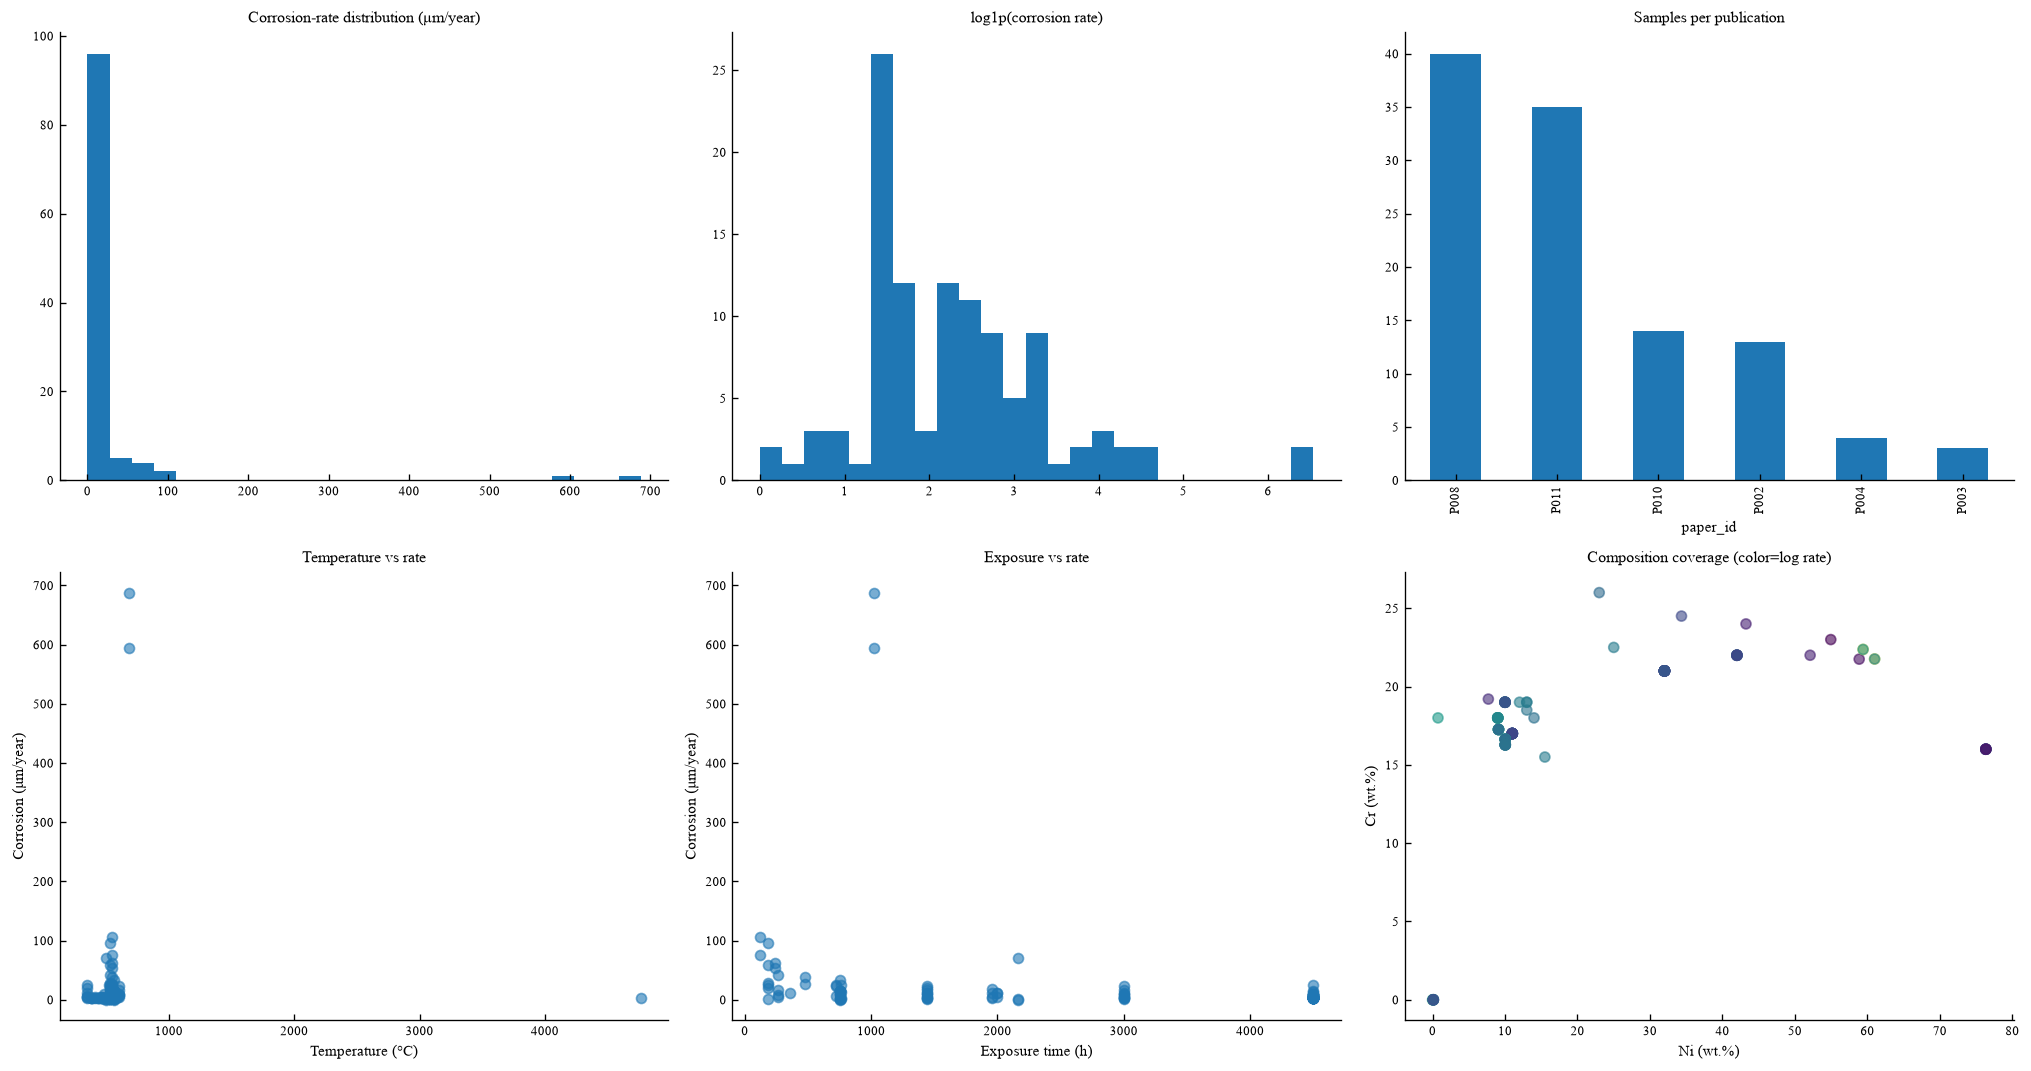

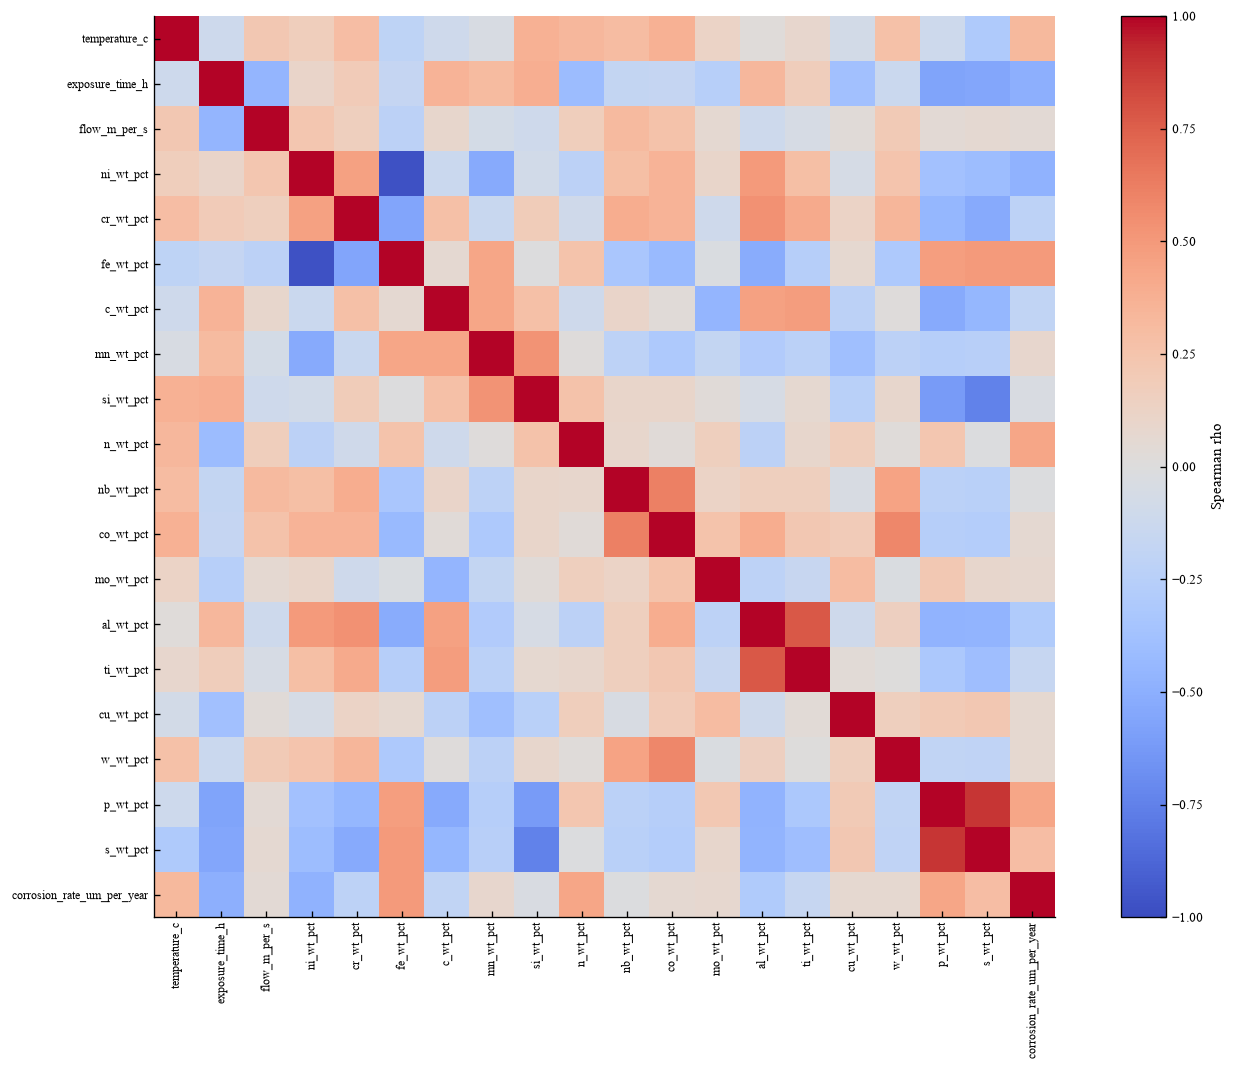

In [42]:
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
y = data.corrosion_rate_um_per_year
axs[0, 0].hist(y, bins=25)
axs[0, 0].set_title("Corrosion-rate distribution (μm/year)")
axs[0, 1].hist(np.log1p(y), bins=25)
axs[0, 1].set_title("log1p(corrosion rate)")
data.paper_id.value_counts().plot(
    kind="bar", ax=axs[0, 2], title="Samples per publication"
)
axs[1, 0].scatter(data.temperature_c, y, alpha=0.6)
axs[1, 0].set(
    xlabel="Temperature (°C)", ylabel="Corrosion (μm/year)", title="Temperature vs rate"
)
axs[1, 1].scatter(data.exposure_time_h, y, alpha=0.6)
axs[1, 1].set(
    xlabel="Exposure time (h)", ylabel="Corrosion (μm/year)", title="Exposure vs rate"
)
axs[1, 2].scatter(data.ni_wt_pct, data.cr_wt_pct, c=np.log1p(y), alpha=0.6)
axs[1, 2].set(
    xlabel="Ni (wt.%)",
    ylabel="Cr (wt.%)",
    title="Composition coverage (color=log rate)",
)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_overview.png", dpi=180)
plt.show()
cor = data[[*COND, *ELEMENTS, "corrosion_rate_um_per_year"]].corr(method="spearman")
plt.figure(figsize=(12, 9))
plt.imshow(cor, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(cor)), cor.columns, rotation=90, fontsize=7)
plt.yticks(range(len(cor)), cor.columns, fontsize=7)
plt.colorbar(label="Spearman rho")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_spearman.png", dpi=180)
plt.show()

## 3. Unified evaluation plan
Random, composition-grouped, and paper-grouped folds each test every observation once. The additional isolated-composition scenario holds out only the five composition profiles farthest from their nearest other profile, one profile per fold. Isolation uses the mean 16-element composition for each existing rounded profile, divided by 100; ties are ordered by profile identifier. These deliberately challenging selected profiles are not a representative sample of all profiles.

For alloy novelty, grouping is based on **full composition**, not on alloy spelling; a study-specific composition can still correlate with study conditions. Publication grouping tests unfamiliar studies, not necessarily unseen alloy compositions. All models use the same outer indices and held-out targets. Nested tuning uses training-only folds.

In [43]:
SCENARIOS = {}
if RUN_RANDOM_SPLIT:
    SCENARIOS["random_row_5fold"] = list(
        KFold(n_splits=5, shuffle=True, random_state=SEED).split(data)
    )
if RUN_ALLOY_SPLIT:
    SCENARIOS["unseen_composition_5fold"] = list(
        GroupKFold(n_splits=min(5, data.composition_profile.nunique())).split(
            data, groups=data.composition_profile
        )
    )
if RUN_STUDY_SPLIT:
    SCENARIOS["unseen_paper_5fold"] = list(
        GroupKFold(n_splits=min(5, data.paper_id.nunique())).split(
            data, groups=data.paper_id
        )
    )

if RUN_ISOLATED_COMPOSITION_SPLIT:
    # Use each existing rounded-profile group, not alloy names, as the unit of novelty.
    profile_means = (
        data.groupby("composition_profile", sort=True)[ELEMENTS].mean() / 100.0
    )
    if len(profile_means) < 5:
        raise ValueError(
            "The isolated-composition scenario requires at least five profiles."
        )
    vectors = profile_means.to_numpy(dtype=float)
    distances = np.linalg.norm(vectors[:, None, :] - vectors[None, :, :], axis=2)
    np.fill_diagonal(distances, np.inf)
    isolated_profiles = (
        pd.DataFrame(
            {
                "composition_profile": profile_means.index,
                "nearest_distance": distances.min(axis=1),
                "test_rows": data.groupby("composition_profile")
                .size()
                .reindex(profile_means.index)
                .to_numpy(),
            }
        )
        .sort_values(
            ["nearest_distance", "composition_profile"],
            ascending=[False, True],
            kind="stable",
        )
        .head(5)
        .reset_index(drop=True)
    )
    display(isolated_profiles)
    profile_labels = data.composition_profile.to_numpy()
    SCENARIOS["isolated_composition_top5"] = [
        (
            np.flatnonzero(profile_labels != profile),
            np.flatnonzero(profile_labels == profile),
        )
        for profile in isolated_profiles.composition_profile
    ]

for scenario, folds in SCENARIOS.items():
    print(scenario, [(len(tr), len(te)) for tr, te in folds])
    held_out = np.concatenate([te for tr, te in folds])
    if scenario == "isolated_composition_top5":
        assert len(np.unique(held_out)) == len(held_out)
        for tr, te in folds:
            assert not np.intersect1d(tr, te).size
            assert sorted(np.concatenate([tr, te])) == list(range(len(data)))
    else:
        assert sorted(held_out) == list(range(len(data)))

,composition_profile,nearest_distance,test_rows
0,43.25|24.00|3.00|0.15|1.00|1.00|0.00|0.00|15.0...,0.188975,1
1,76.35|16.00|7.20|0.02|0.42|0.00|0.00|0.00|0.00...,0.188812,7
2,58.87|21.75|15.80|0.03|0.21|0.13|0.00|0.00|0.0...,0.146017,1
3,34.35|24.50|30.00|0.10|1.50|1.00|0.00|0.35|0.0...,0.120910,1
4,42.00|22.00|29.97|0.02|0.50|0.00|0.00|0.00|0.0...,0.120910,7


random_row_5fold [(87, 22), (87, 22), (87, 22), (87, 22), (88, 21)]
unseen_composition_5fold [(87, 22), (87, 22), (87, 22), (87, 22), (88, 21)]
unseen_paper_5fold [(69, 40), (74, 35), (95, 14), (96, 13), (102, 7)]
isolated_composition_top5 [(108, 1), (102, 7), (108, 1), (108, 1), (102, 7)]


## 4. Shared 22-feature input specification and model-specific preprocessing

All five models use **exactly 22 source predictors**: temperature, exposure time, flow velocity, 16 elemental weight percentages (Ni, Cr, Fe, C, Mn, Si, N, Nb, Co, Mo, Al, Ti, Cu, W, P, S), and one-hot indicators for air, N₂ and O₂ (sealed loop). Exposure time is transformed to `log1p(time)` for **all** models. Its transformation is deterministic and does not estimate statistics from held-out data.

**SVR, GPR, MLP and Fusion ANN** all consume these 22 features. **Fusion VQC** uses them through staged repeated encoding on six logical qubits; qubit count is not the number of input variables. Preprocessing parameters are always fit on training folds only. The shared target is `log1p(corrosion rate)`, and reported MAE/RMSE/R² are calculated after inversion to μm/year. Inverse-transformed negative predictions are clipped to zero.


In [44]:
# ============================================================
# SHARED FEATURE DEFINITIONS FOR ALL MODELS
# ============================================================

# Chemistry: 16 elemental composition features
CHEM = ELEMENTS.copy()

# Experimental conditions: 3 numerical + 3 headgas features
CONDITIONS = COND + GASES

# Unified feature list: exactly 22 features
ALL = CHEM + CONDITIONS

# Validate feature consistency
assert len(ALL) == 22, f"Expected 22 features, got {len(ALL)}"
assert len(set(ALL)) == 22, "Duplicate features detected"

assert set(ALL) == set(FULL_FEATURES), (
    "Models must consume exactly the same 22 source features"
)

# Ensure every feature exists in the cleaned dataset
missing = set(ALL) - set(data.columns)

if missing:
    raise ValueError(f"Missing features: {sorted(missing)}")


# Shared feature extraction function
def feature_frame(frame):
    """Select the current model features as floating-point values."""
    return frame[ALL].astype(float)


# Final checks
print("Feature validation successful!")
print("Total input features:", len(ALL))
print("Chemistry features:", len(CHEM))
print("Condition features:", len(CONDITIONS))

print("\nFeature names:")
for i, feature in enumerate(ALL, start=1):
    print(f"{i:2d}. {feature}")

Feature validation successful!
Total input features: 22
Chemistry features: 16
Condition features: 6

Feature names:
 1. ni_wt_pct
 2. cr_wt_pct
 3. fe_wt_pct
 4. c_wt_pct
 5. mn_wt_pct
 6. si_wt_pct
 7. n_wt_pct
 8. nb_wt_pct
 9. co_wt_pct
10. mo_wt_pct
11. al_wt_pct
12. ti_wt_pct
13. cu_wt_pct
14. w_wt_pct
15. p_wt_pct
16. s_wt_pct
17. temperature_c
18. exposure_time_h
19. flow_m_per_s
20. headgas_air
21. headgas_n2
22. headgas_o2_sealed_loop


In [45]:

CHEM = ELEMENTS
CONDITIONS = ["temperature_c", "log_time", "flow_m_per_s"] + GASES
ALL = CHEM + CONDITIONS
assert len(ALL) == 22 and len(set(ALL)) == 22
# ALL includes log_time in place of the raw exposure-time feature.


def classical_pipeline(model_name):
    """Build the preprocessing and regression pipeline for a kernel model."""
    # percentage features /100 to preserve original SVR composition engineering
    pre = ColumnTransformer(
        [
            ("physical", StandardScaler(), CONDITIONS[:3]),
            (
                "chemistry",
                FunctionTransformer(lambda z: z / 100.0, validate=False),
                CHEM,
            ),
        ],
        remainder="passthrough",
    )
    # pre output is conditions first, elements second, headgas last
    if model_name == "SVR":
        return Pipeline([("pre", pre), ("reg", SVR(kernel="rbf"))])
    # modest jitter for duplicate predictor rows; kernel is RBF+WhiteKernel
    if model_name == "GPR":
        return Pipeline(
            [
                ("pre", pre),
                (
                    "reg",
                    GaussianProcessRegressor(
                        kernel=ConstantKernel(1.0, (1e-2, 1e3)) * RBF(1.0, (1e-2, 1e3))
                        + WhiteKernel(0.1, (1e-5, 10)),
                        alpha=1e-6,
                        normalize_y=True,
                        n_restarts_optimizer=1,
                        random_state=SEED,
                    ),
                ),
            ]
        )
    raise KeyError(model_name)


def internal_cv(frame, scenario):
    """Select cross-validation folds and groups for the scenario."""
    if scenario == "unseen_paper_5fold":
        groups = frame.paper_id
    elif scenario in ("unseen_composition_5fold", "isolated_composition_top5"):
        groups = frame.composition_profile
    else:
        return KFold(n_splits=min(3, len(frame)), shuffle=True, random_state=SEED), None
    if groups.nunique() < 2:
        return KFold(n_splits=min(3, len(frame)), shuffle=True, random_state=SEED), None
    return GroupKFold(n_splits=min(3, groups.nunique())), groups


def predict_kernel(name, tr, te, scenario):
    """Fit a kernel model on training rows and predict corrosion rates."""
    pipe = classical_pipeline(name)
    ytr = np.log1p(tr.corrosion_rate_um_per_year.to_numpy())
    if name == "SVR":
        grid = {
            "reg__C": [0.1, 1, 10, 100, 1000],
            "reg__gamma": [0.001, 0.01, 0.1, 1, "scale"],
            "reg__epsilon": [0.01, 0.1, 0.5],
        }
    else:
        grid = {
            "reg__kernel": [
                ConstantKernel(1.0) * RBF(1.0) + WhiteKernel(0.1),
                ConstantKernel(1.0) * Matern(1.5, nu=1.5) + WhiteKernel(0.1),
            ]
        }
    if RUN_NESTED_TUNING:
        cv, groups = internal_cv(tr, scenario)
        search = GridSearchCV(
            pipe,
            grid,
            cv=cv,
            scoring="neg_mean_absolute_error",
            n_jobs=-1 if name == "SVR" else 1,
            refit=True,
        )
        search.fit(
            feature_frame(tr), ytr, **({"groups": groups} if groups is not None else {})
        )
        model = search.best_estimator_
    else:
        model = pipe.fit(feature_frame(tr), ytr)
    p = model.predict(feature_frame(te))
    return np.maximum(0, np.expm1(np.clip(p, -20, 12)))


def predict_baseline(name, tr, te):
    """Fit a baseline model on training rows and predict corrosion rates."""
    # Fit all preprocessing and the estimator only on this outer training fold.
    if name == "Random Forest":
        estimator = RandomForestRegressor(
            n_estimators=100, random_state=SEED, n_jobs=-1
        )
    else:
        raise KeyError(name)
    model = Pipeline([("scale", StandardScaler()), ("reg", estimator)])
    ytr = np.log1p(tr.corrosion_rate_um_per_year.to_numpy())
    model.fit(feature_frame(tr), ytr)
    p = model.predict(feature_frame(te))
    return np.maximum(0, np.expm1(np.clip(p, -20, 12)))


def prepare_ann(tr, te):
    """Scale chemistry and condition inputs for neural network models."""
    out = []
    for cols in (CHEM, CONDITIONS):
        scale = StandardScaler()
        out.append(
            (
                torch.tensor(
                    np.clip(scale.fit_transform(tr[cols]), -5, 5), dtype=torch.float32
                ),
                torch.tensor(
                    np.clip(scale.transform(te[cols]), -5, 5), dtype=torch.float32
                ),
            )
        )
    return out


class SimpleMLP(nn.Module):
    """Predict log corrosion rates from concatenated features."""

    def __init__(self, n):
        """Initialize the network for n input features."""
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n, 16), nn.SiLU(), nn.Linear(16, 8), nn.SiLU(), nn.Linear(8, 1)
        )

    def forward(self, x):
        """Compute predictions for a batch of features."""
        return self.net(x)


class FusionANN(nn.Module):
    """Combine separate chemistry and condition representations."""

    def __init__(self, nchem, ncond):
        """Initialize the two input branches and output network."""
        super().__init__()
        self.chemistry = nn.Sequential(nn.Linear(nchem, 16), nn.SiLU())
        self.conditions = nn.Sequential(nn.Linear(ncond, 8), nn.SiLU())
        self.output = nn.Sequential(nn.Linear(24, 16), nn.SiLU(), nn.Linear(16, 1))

    def forward(self, a, b):
        """Compute predictions from chemistry and condition batches."""
        return self.output(torch.cat([self.chemistry(a), self.conditions(b)], dim=1))


def predict_ann(name, tr, te):
    """Train a neural network and predict corrosion rates."""
    torch.set_default_dtype(torch.float32)
    torch.manual_seed(SEED)
    (a, b), (c, d) = prepare_ann(tr, te)
    model = (
        SimpleMLP(a.shape[1] + c.shape[1])
        if name == "MLP"
        else FusionANN(a.shape[1], c.shape[1])
    )
    args_tr = (torch.cat([a, c], dim=1),) if name == "MLP" else (a, c)
    args_te = (torch.cat([b, d], dim=1),) if name == "MLP" else (b, d)
    y = torch.tensor(
        np.log1p(tr.corrosion_rate_um_per_year.to_numpy()), dtype=torch.float32
    ).view(-1, 1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
    model.train()
    for _ in range(1500):
        optimizer.zero_grad()
        loss = nn.HuberLoss()(model(*args_tr), y)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        p = model(*args_te).numpy().reshape(-1)
    return np.maximum(0, np.expm1(np.clip(p, -20, 12)))

### 4.1 Preserved quantum fusion circuit
Taken from your `quantum_IDS.ipynb`: six logical qubits (chemistry 0–2, conditions 3–5), two circuit stages, CNOT interactions across registers, mid-circuit measurements with reset, conditional feed-forward, Pauli-Z readout and trainable classical linear output. Numerical feature scaling remains **train-fold MinMax to [0,π]**, as in your VQC, and the loss remains Huber(δ=0.5), AdamW, 60 epochs, batch 16. The analytic simulator uses eight wires to support deferred measurement; this does **not** imply a physical-qubit efficiency claim.

In [46]:
!pip install pennylane --upgrade

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [47]:
# PennyLane is required only for quantum evaluations
if RUN_QUANTUM:
    import pennylane as qml

    torch.set_default_dtype(torch.float64)
    CHEM_WIRES = (0, 1, 2)
    COND_WIRES = (3, 4, 5)
    N_WIRES = 6

In [48]:
if RUN_QUANTUM:
    # One quantum circuit shared by every observation and all training steps.
    # Mid-circuit reset and conditional operations are part of this SAME circuit.
    # qml.qnode with torch/backprop works for analytic expectation values on
    # supported PennyLane versions; if backend support differs, see run notes.
    # Two extra simulator wires support deferral of the two reset measurements.
    # Only wires 0..5 are logical data qubits in the authored quantum circuit.
    DEVICE = qml.device("default.qubit", wires=N_WIRES + 2, shots=None)

    @qml.qnode(DEVICE, interface="torch", diff_method="backprop", mcm_method="deferred")
    def fusion_circuit(xchem, xcond, theta, feedback):
        """Encode features and return quantum circuit expectation values."""
        # Stage 1: two feature sets enter separate 3-qubit registers.
        # Pack arbitrarily many features by alternating encoding rotations,
        # so EVERY available elemental composition is represented.
        split_chem = (len(xchem) + 1) // 2
        split_cond = (len(xcond) + 1) // 2
        for j in range(split_chem):
            wire = CHEM_WIRES[j % 3]
            qml.RY(xchem[j], wires=wire)
            qml.RZ(0.5 * xchem[j], wires=wire)
        for j in range(split_cond):
            wire = COND_WIRES[j % 3]
            qml.RY(xcond[j], wires=wire)
            qml.RZ(0.5 * xcond[j], wires=wire)
        for w in range(N_WIRES):
            qml.RY(theta[0, w, 0], wires=w)
            qml.RZ(theta[0, w, 1], wires=w)
        # Intra-register then cross-register information exchange.
        for a, b in ((0, 1), (1, 2), (3, 4), (4, 5)):
            qml.CNOT(wires=[a, b])
        for a, b in ((0, 3), (1, 4), (2, 5)):
            qml.CNOT(wires=[a, b])

        # Stage 2: measure, reset, and REUSE q0/q3. The other qubits retain
        # information from the pre-measurement circuit. Outcomes supply feed-forward.
        m_chem = qml.measure(0, reset=True)
        m_cond = qml.measure(3, reset=True)
        qml.cond(m_chem, qml.RY)(feedback[0], wires=1)
        qml.cond(m_cond, qml.RY)(feedback[1], wires=4)

        # Encode remaining chemistry and condition features on the same register;
        # start at newly reset wires to make reuse explicit.
        for j in range(split_chem, len(xchem)):
            wire = CHEM_WIRES[(j - split_chem) % 3]
            qml.RY(xchem[j], wires=wire)
            qml.RZ(0.5 * xchem[j], wires=wire)
        for j in range(split_cond, len(xcond)):
            wire = COND_WIRES[(j - split_cond) % 3]
            qml.RY(xcond[j], wires=wire)
            qml.RZ(0.5 * xcond[j], wires=wire)

        for w in range(N_WIRES):
            qml.RY(theta[1, w, 0], wires=w)
            qml.RZ(theta[1, w, 1], wires=w)
        for a, b in ((0, 1), (1, 2), (3, 4), (4, 5), (0, 3), (1, 4), (2, 5)):
            qml.CNOT(wires=[a, b])
        return tuple(qml.expval(qml.PauliZ(w)) for w in range(N_WIRES))

In [49]:
if RUN_QUANTUM:

    class SingleFusionVQC(nn.Module):
        """Combine a shared quantum circuit with a linear readout."""

        def __init__(self, target_mean=0.0):
            """Initialize circuit parameters and the classical readout."""
            super().__init__()
            self.theta = nn.Parameter(0.1 * torch.randn(2, N_WIRES, 2))
            self.feedback = nn.Parameter(0.1 * torch.randn(2))
            # Classical linear regression readout ONLY; this is not a second circuit.
            self.readout = nn.Linear(N_WIRES, 1)
            with torch.no_grad():
                self.readout.weight.mul_(0.1)
                self.readout.bias.fill_(float(target_mean))

        def forward(self, xchem, xcond):
            """Predict log corrosion rates for a batch of inputs."""
            out = []
            for a, b in zip(xchem, xcond):
                z = fusion_circuit(a, b, self.theta, self.feedback)
                out.append(torch.stack(z))
            return self.readout(torch.stack(out)).squeeze(-1)

    def train(model, xchem, xcond, y, *, epochs, lr, batch_size):
        """Train the quantum model in batches using Huber loss."""
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
        criterion = nn.HuberLoss(delta=0.5)
        model.train()
        for epoch in range(epochs):
            order = torch.randperm(len(y))
            epoch_loss = 0.0
            for idx in order.split(batch_size):
                opt.zero_grad()
                pred = model(xchem[idx], xcond[idx])
                loss = criterion(pred, y[idx])
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                opt.step()
                epoch_loss += loss.item() * len(idx)
            if epoch == 0 or (epoch + 1) % 10 == 0:
                print(
                    f"epoch {epoch + 1:4d}/{epochs}: "
                    f"train Huber(log)={epoch_loss / len(y):.5f}",
                    flush=True,
                )
        return model

In [50]:
def predict_quantum(tr, te):
    """Train the quantum model and predict corrosion rates."""
    if not RUN_QUANTUM:
        raise RuntimeError("RUN_QUANTUM=False")
    torch.set_default_dtype(torch.float64)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    def scale(cols):
        m = MinMaxScaler().fit(tr[cols])
        a = m.transform(tr[cols])
        b = m.transform(te[cols])
        return torch.as_tensor(
            np.clip(a, 0, 1) * np.pi, dtype=torch.float64
        ), torch.as_tensor(np.clip(b, 0, 1) * np.pi, dtype=torch.float64)

    ca, cb = scale(CHEM)
    xa, xb = scale(CONDITIONS)
    y = torch.as_tensor(
        np.log1p(tr.corrosion_rate_um_per_year.to_numpy()), dtype=torch.float64
    )
    model = SingleFusionVQC(target_mean=y.mean().item())
    train(
        model, ca, xa, y, epochs=QUANTUM_EPOCHS, lr=0.01, batch_size=QUANTUM_BATCH_SIZE
    )
    model.eval()
    with torch.no_grad():
        pr = model(cb, xb).cpu().numpy()
    return np.maximum(0, np.expm1(np.clip(pr, -20, 12)))

## 5. Run all outer folds and score identically
Export one record per held-out observation per model and scenario. **MAE, RMSE, and R²** are evaluated in original corrosion units. Log-scale MAE is a supplementary metric; for publication holdouts the aggregate R² can hide per-study failures, so per-fold results are also exported.

In [51]:
def run_benchmark(frame, tag="main"):
    """Evaluate models across scenarios and save predictions and metrics."""
    methods = ["Random Forest", "SVR", "GPR", "MLP", "Fusion ANN"] + (
        ["Fusion VQC"] if RUN_QUANTUM else []
    )
    predictions = []
    metrics = []
    for scenario, folds in SCENARIOS.items():
        for fold, (train_i, test_i) in enumerate(folds, 1):
            tr = frame.iloc[train_i].copy()
            te = frame.iloc[test_i].copy()
            for name in methods:
                print(
                    f">>> {tag} {scenario} fold {fold}/{len(folds)} {name}", flush=True
                )
                if name in ("Random Forest"):
                    p = predict_baseline(name, tr, te)
                elif name in ("SVR", "GPR"):
                    p = predict_kernel(name, tr, te, scenario)
                elif name in ("MLP", "Fusion ANN"):
                    p = predict_ann(name, tr, te)
                else:
                    p = predict_quantum(tr, te)
                if len(p) != len(te):
                    raise ValueError("Prediction length mismatch")
                truth = te.corrosion_rate_um_per_year.to_numpy()
                metrics.append(
                    dict(
                        run=tag,
                        scenario=scenario,
                        fold=fold,
                        model=name,
                        n=len(te),
                        MAE=mean_absolute_error(truth, p),
                        RMSE=np.sqrt(mean_squared_error(truth, p)),
                        R2=r2_score(truth, p) if len(truth) > 1 else np.nan,
                        log_MAE=mean_absolute_error(np.log1p(truth), np.log1p(p)),
                    )
                )
                for localidx, actual, pred in zip(test_i, truth, p):
                    obs = frame.iloc[localidx]
                    predictions.append(
                        dict(
                            run=tag,
                            scenario=scenario,
                            fold=fold,
                            model=name,
                            source_row=int(obs.source_row),
                            row_index=int(localidx),
                            paper_id=obs.paper_id,
                            alloy=obs.alloy,
                            composition_profile=obs.composition_profile,
                            actual_um_yr=float(actual),
                            predicted_um_yr=float(pred),
                            censored_proxy=bool(obs.censored_rate),
                        )
                    )
    preds = pd.DataFrame(predictions)
    folds_df = pd.DataFrame(metrics)
    summary = []
    for (scenario, name), g in preds.groupby(["scenario", "model"], sort=False):
        y = g.actual_um_yr.to_numpy()
        p = g.predicted_um_yr.to_numpy()
        summary.append(
            dict(
                run=tag,
                scenario=scenario,
                model=name,
                n=len(g),
                MAE=mean_absolute_error(y, p),
                RMSE=np.sqrt(mean_squared_error(y, p)),
                R2=r2_score(y, p),
                log_MAE=mean_absolute_error(np.log1p(y), np.log1p(p)),
            )
        )
    summary = pd.DataFrame(summary).sort_values(["scenario", "MAE"])
    preds.to_csv(OUTPUT_DIR / f"{tag}_predictions.csv", index=False)
    folds_df.to_csv(OUTPUT_DIR / f"{tag}_fold_metrics.csv", index=False)
    summary.to_csv(OUTPUT_DIR / f"{tag}_summary.csv", index=False)
    return summary, folds_df, preds


summary, fold_scores, preds = run_benchmark(data)
display(summary)

>>> main random_row_5fold fold 1/5 Random Forest
>>> main random_row_5fold fold 1/5 SVR
>>> main random_row_5fold fold 1/5 GPR
>>> main random_row_5fold fold 1/5 MLP
>>> main random_row_5fold fold 1/5 Fusion ANN
>>> main random_row_5fold fold 2/5 Random Forest
>>> main random_row_5fold fold 2/5 SVR
>>> main random_row_5fold fold 2/5 GPR
>>> main random_row_5fold fold 2/5 MLP
>>> main random_row_5fold fold 2/5 Fusion ANN
>>> main random_row_5fold fold 3/5 Random Forest
>>> main random_row_5fold fold 3/5 SVR
>>> main random_row_5fold fold 3/5 GPR
>>> main random_row_5fold fold 3/5 MLP
>>> main random_row_5fold fold 3/5 Fusion ANN
>>> main random_row_5fold fold 4/5 Random Forest
>>> main random_row_5fold fold 4/5 SVR
>>> main random_row_5fold fold 4/5 GPR
>>> main random_row_5fold fold 4/5 MLP
>>> main random_row_5fold fold 4/5 Fusion ANN
>>> main random_row_5fold fold 5/5 Random Forest
>>> main random_row_5fold fold 5/5 SVR
>>> main random_row_5fold fold 5/5 GPR
>>> main random_row_5fold

,run,scenario,model,n,MAE,RMSE,R2,log_MAE
15,main,isolated_composition_top5,Random Forest,17,5.395495,8.868002,-1.079992,0.784224
17,main,isolated_composition_top5,GPR,17,5.593443,7.559609,-0.511502,0.936907
16,main,isolated_composition_top5,SVR,17,5.597771,7.326574,-0.419751,1.002338
19,main,isolated_composition_top5,Fusion ANN,17,9.113365,17.067142,-6.704274,1.040688
18,main,isolated_composition_top5,MLP,17,128.447863,325.631238,-2803.543824,2.174011
2,main,random_row_5fold,GPR,109,9.476288,35.294633,0.833344,0.485619
0,main,random_row_5fold,Random Forest,109,16.724459,80.820947,0.126123,0.487007
4,main,random_row_5fold,Fusion ANN,109,19.232775,76.236269,0.222455,0.512100
3,main,random_row_5fold,MLP,109,22.934635,97.459778,-0.270730,0.470443
1,main,random_row_5fold,SVR,109,30.660171,160.650271,-2.452751,0.484616


## 6. Comparative graphics, extrapolation diagnostics and reporting

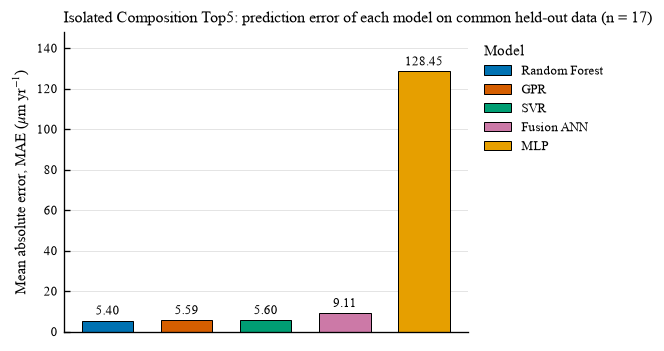

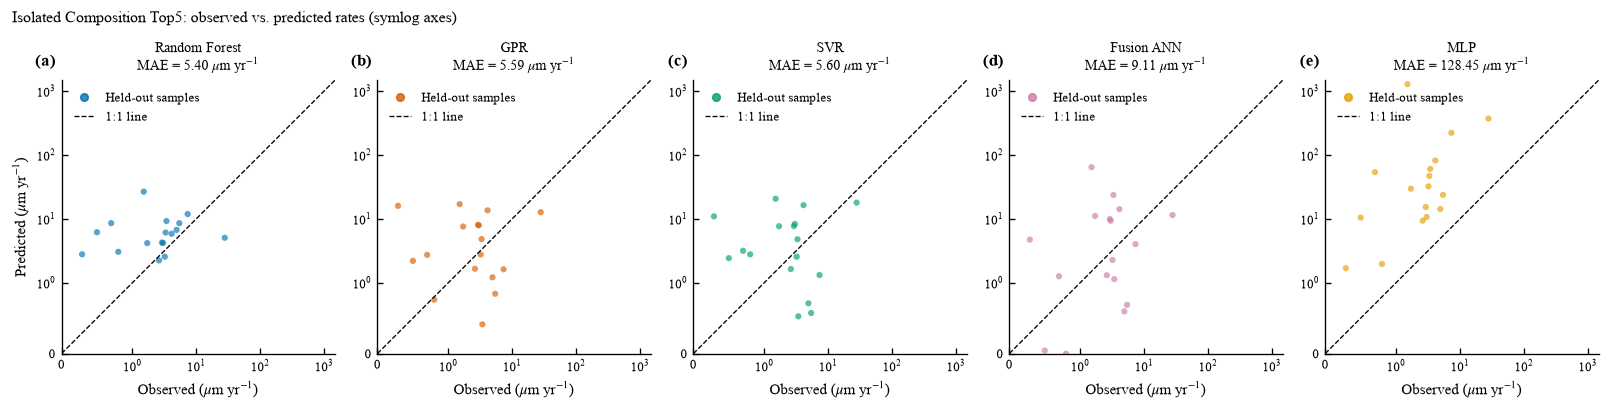

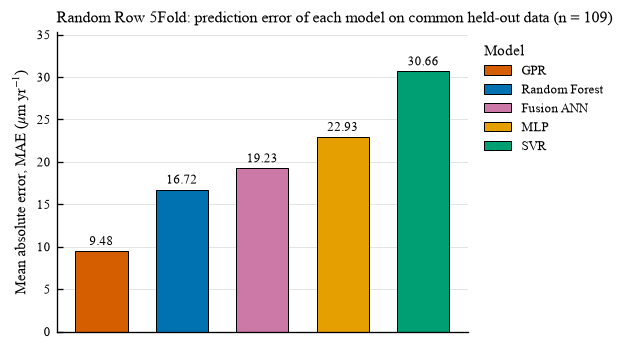

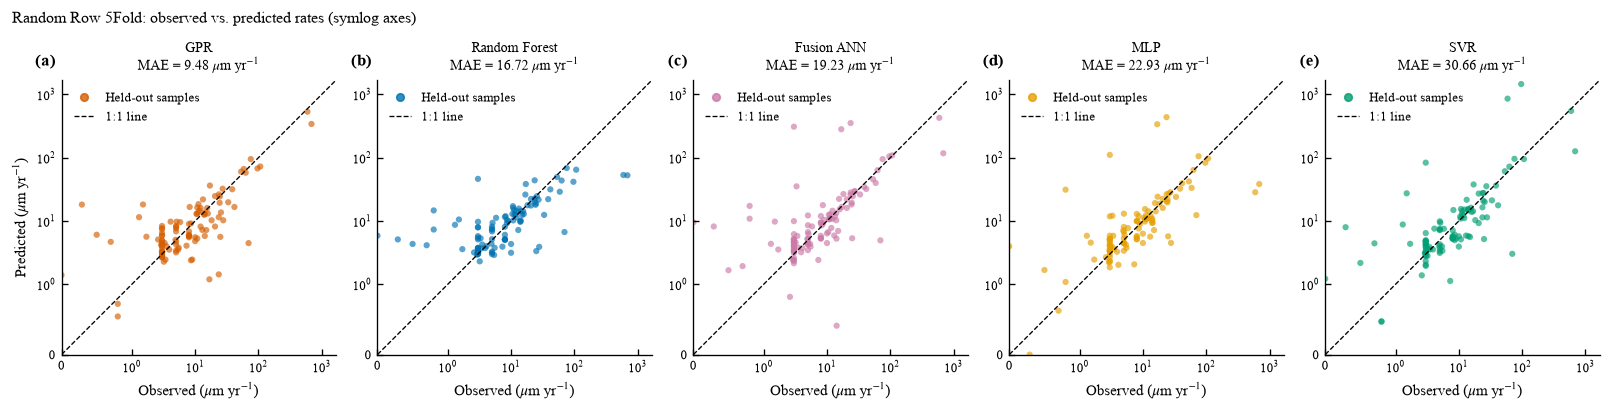

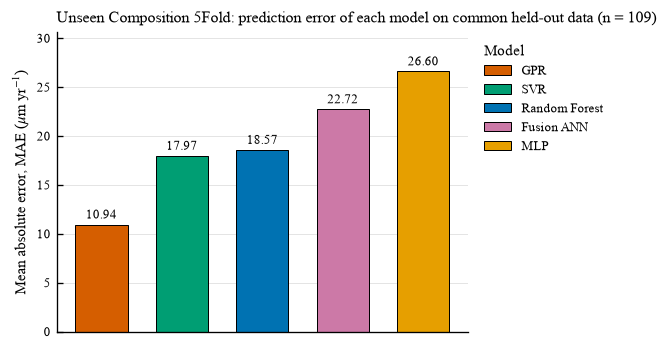

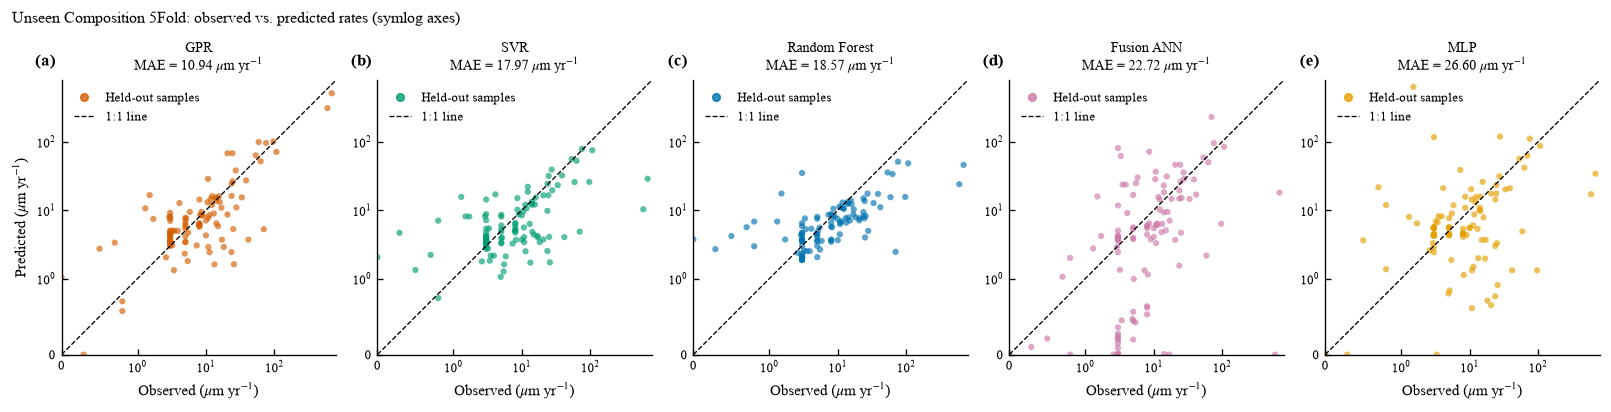

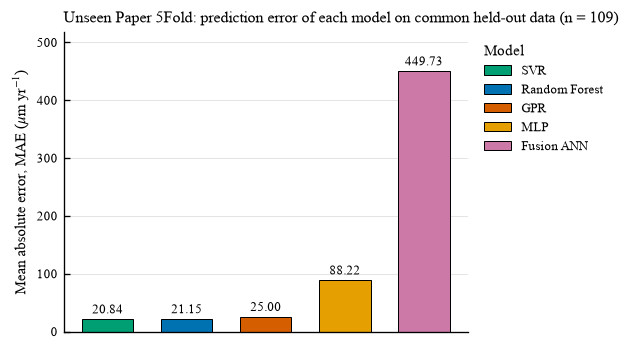

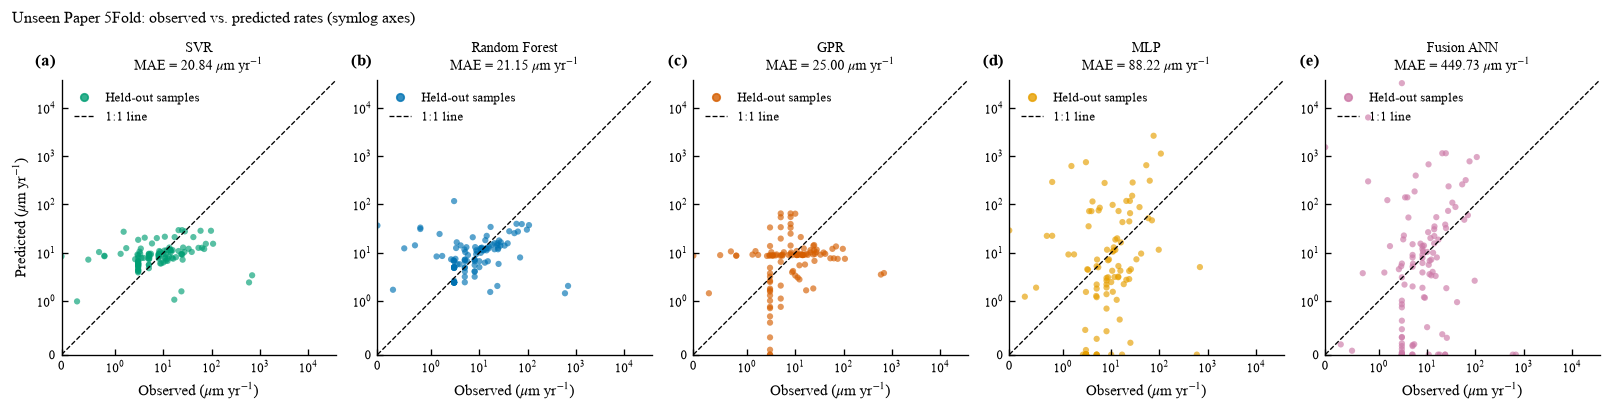

Outputs saved under D:\Documents\Coding Projects\molten_salt\content\corrosion_unified_results


In [52]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ---------- Journal-style defaults ----------
mpl.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 9.5,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "axes.linewidth": 0.8,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
        "figure.dpi": 120,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,  # editable text in vector output
    }
)

# ---------- One color per model, shared by every figure ----------
# Okabe-Ito palette (colorblind-safe, prints well in grayscale)
OKABE_ITO = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
    "#56B4E9",
    "#F0E442",
    "#000000",
]
all_models = list(dict.fromkeys(summary.model))  # fixed order of appearance
palette = OKABE_ITO if len(all_models) <= len(OKABE_ITO) else plt.cm.tab20.colors
MODEL_COLORS = {m: palette[i % len(palette)] for i, m in enumerate(all_models)}


def pretty(s):
    """Format an identifier as a title for plots."""
    return str(s).replace("_", " ").strip().title()


def save(fig, stem):
    """Save a figure in PNG and PDF formats."""
    for ext in ("png", "pdf"):
        fig.savefig(OUTPUT_DIR / f"{stem}.{ext}")


def panel_label(ax, text):
    """Place a panel label above an axes."""
    ax.text(
        -0.02,
        1.04,
        text,
        transform=ax.transAxes,
        fontsize=10,
        fontweight="bold",
        va="bottom",
        ha="right",
    )


for scenario, group in summary.groupby("scenario", sort=False):
    sc = pretty(scenario)
    models = list(group.model)
    n_eval = int(group["n"].iloc[0]) if "n" in group.columns else None
    n_txt = f" (n = {n_eval})" if n_eval else ""

    # ---------- Figure 1: MAE bar chart ----------
    fig, ax = plt.subplots(figsize=(3.5 + 0.35 * len(models), 3.0))
    x = np.arange(len(models))
    bars = ax.bar(
        x,
        group.MAE,
        width=0.65,
        color=[MODEL_COLORS[m] for m in models],
        edgecolor="black",
        linewidth=0.6,
    )
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=7.5)
    ax.set_xticks([])  # identification via legend
    ax.set_ylabel(r"Mean absolute error, MAE ($\mu$m yr$^{-1}$)")
    ax.set_ylim(0, group.MAE.max() * 1.15)
    ax.yaxis.grid(True, linewidth=0.4, alpha=0.5)
    ax.set_axisbelow(True)
    ax.set_title(
        f"{sc}: prediction error of each model on common held-out data{n_txt}",
        loc="left",
    )
    ax.legend(
        handles=[
            Patch(facecolor=MODEL_COLORS[m], edgecolor="black", linewidth=0.6, label=m)
            for m in models
        ],
        title="Model",
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        alignment="left",
    )
    fig.tight_layout()
    save(fig, f"{scenario}_mae")
    plt.show()

    # ---------- Figure 2: observed vs predicted ----------
    k = len(models)
    fig, axs = plt.subplots(1, k, figsize=(2.7 * k, 3.1), squeeze=False)
    sub = preds[preds.scenario == scenario]
    lim = max(sub.actual_um_yr.max(), sub.predicted_um_yr.max(), 1) * 1.15
    for i, (ax, (_, entry)) in enumerate(zip(axs[0], group.iterrows())):
        ss = sub[sub.model == entry.model]
        ax.scatter(
            ss.actual_um_yr,
            ss.predicted_um_yr,
            s=14,
            alpha=0.65,
            color=MODEL_COLORS[entry.model],
            edgecolor="none",
            rasterized=True,
        )
        ax.plot([0, lim], [0, lim], color="black", linestyle="--", linewidth=0.8)
        ax.set_xscale("symlog", linthresh=1)
        ax.set_yscale("symlog", linthresh=1)
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel(r"Observed ($\mu$m yr$^{-1}$)")
        if i == 0:
            ax.set_ylabel(r"Predicted ($\mu$m yr$^{-1}$)")
        ax.set_title(
            f"{entry.model}\nMAE = {entry.MAE:.2f} $\\mu$m yr$^{{-1}}$", fontsize=8.5
        )
        ax.legend(
            handles=[
                Line2D(
                    [],
                    [],
                    marker="o",
                    linestyle="",
                    markersize=4.5,
                    color=MODEL_COLORS[entry.model],
                    alpha=0.8,
                    label="Held-out samples",
                ),
                Line2D(
                    [],
                    [],
                    color="black",
                    linestyle="--",
                    linewidth=0.8,
                    label="1:1 line",
                ),
            ],
            loc="upper left",
            handlelength=1.6,
        )
        panel_label(ax, f"({chr(97 + i)})")
    fig.suptitle(
        f"{sc}: observed vs. predicted rates (symlog axes)",
        x=0.01,
        ha="left",
        fontsize=9.5,
        y=1.02,
    )
    fig.tight_layout()
    save(fig, f"{scenario}_scatter")
    plt.show()

print("Outputs saved under", OUTPUT_DIR.resolve())

## 7. Sensitivity analyses and reporting limitations
**Primary analysis**: upper-censored `<3` → 3 μm/year, mirroring your provided quantum v2. **Alternative**: substitute 1.5 and rerun all models and same folds. Neither is a principled censored regression likelihood, so this uncertainty must be disclosed. The flagged 4765°C datum should be corrected only after checking the source; do not claim physically valid extrapolation from it. For rigorous publication, consider repeating the entire experiment after an independently justified source correction, and report foldwise/per-study errors, train/test feature-range overlap, and cross-study confounding. Headgas distinctions are preserved, rather than collapsing air and oxygen, for all models.

In [53]:
if RUN_SENSITIVITY:
    alternative, _ = load_clean(censored_proxy=1.5)
    if not (alternative.source_row.to_numpy() == data.source_row.to_numpy()).all():
        raise ValueError("Sensitivity rows differ!")
    alt_summary, alt_folds, alt_preds = run_benchmark(
        alternative, tag="censored_half_bound"
    )
    display(alt_summary)

## Reproducibility notes
- Ensure all enabled models run on **identical source rows**, target proxies and holdouts; full-coverage scenarios test every row, while the isolated-profile scenario tests only its five selected profiles.
- The previous GPR experiment kept 4765°C, while the earlier MLP excluded some censored target data. **Old reported scores must not be copied into this table.**
- A seeded random forest was used as a baseline model. Classical SVR RBF, GP kernels, original MLP 16→8, two-branch fusion ANN 16/8→16, and the supplied single-circuit VQC remain distinct.
- **Feature fairness vs architecture fidelity:** the single-circuit quantum fusion approach uses the same **22 underlying predictor values** by repeated angle encoding, but each model transforms them differently. A separate controlled feature-ablation study (e.g. all models on only six physically chosen variables) could isolate the effect of input representation; it is **not** the primary architectural comparison.
- Sampling uncertainty matters: strong causal or quantum-advantage conclusions are not supported by this small non-independent dataset alone.